In [2]:
%load_ext autoreload
%autoreload 2
from services import skraafoto
import georeferencing  as geo
import matplotlib.pyplot as plt
from utils import plots, image_handler
import random 

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# lat long to pixel with tiling - old (without saved data)

In [3]:
stac_item_id = "2023_82_16_2_0004_00003756"
item = skraafoto.fetch_skraafoto_item(stac_item_id)
item

HTTPError: 400 Client Error: Bad Request for url: https://api.dataforsyningen.dk/rest/skraafoto_api/v1.0/collections/skraafotos2023/items/2023_82_16_2_0004_00003756

In [3]:
image = image_handler.convert_img_to_byte_array(image_handler.extract_selected_image(item))

In [5]:
tiles_test = geo.split_image_by_latlon(item,image,4,4)
tiles_test

{'2023_82_16_2_0004_00003756': [TileData(tile_image_path='', tile_bounds_latlon={'lat_min': np.float64(56.44316104991162), 'lat_max': np.float64(56.445658342978376), 'lon_min': np.float64(10.02735779313822), 'lon_max': np.float64(10.032126069873804)}, pixel_bounds={'x_min': 0, 'x_max': 2031, 'y_min': 0, 'y_max': 2398}, homography=array([[ 6.30327663e-05, -3.85900830e-04,  1.00297968e+01],
         [ 3.47319340e-04, -2.16949189e-03,  5.64433065e+01],
         [ 6.15364831e-06, -3.84527749e-05,  1.00000000e+00]])),
  TileData(tile_image_path='', tile_bounds_latlon={'lat_min': np.float64(56.44316104991162), 'lat_max': np.float64(56.445658342978376), 'lon_min': np.float64(10.032126069873804), 'lon_max': np.float64(10.03689434660939)}, pixel_bounds={'x_min': 1774, 'x_max': 5431, 'y_min': 0, 'y_max': 2474}, homography=array([[ 3.23415439e-05, -3.74561010e-04,  1.00297283e+01],
         [ 1.74447221e-04, -2.10574508e-03,  5.64433097e+01],
         [ 3.09086838e-06, -3.73231841e-05,  1.0000000

Random Pixel to Convert: (2096, 1773)
Bounding Box in Pixels: x_min=0, x_max=2031, y_min=0, y_max=2398
Checking if (2096, 1773) falls inside...

Bounding Box in Pixels: x_min=1774, x_max=5431, y_min=0, y_max=2474
Checking if (2096, 1773) falls inside...

Projected lon lat: (np.float64(10.032303335887796), np.float64(56.44497880548889))
Type of img: <class 'requests.models.Response'>


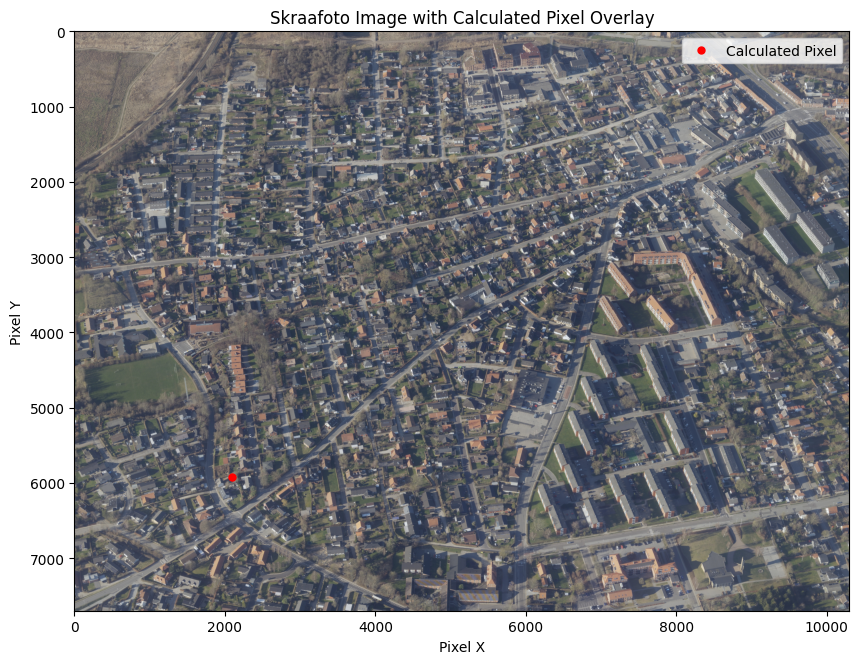

lat: 56.44497880548889
lon10.032303335887796


In [ ]:
random_pixel_x = random.randint(0, image.shape[1] - 1)
random_pixel_y = random.randint(0, image.shape[0] - 1)

print(f"Random Pixel to Convert: {random_pixel_x, random_pixel_y}")

tile = geo.get_tile_for_pixel(random_pixel_x, random_pixel_y, stac_item_id, tiles_test)
projected_points = geo.convert_pixel_to_world_homography(random_pixel_x,random_pixel_y, tile.homography)
print(f"Projected lon lat: {projected_points}")

img = skraafoto.get_image_from_url(image_handler.extract_selected_image(item))
print(f"Type of img: {type(img)}")  

plots.plot_pixel_on_image([random_pixel_x,random_pixel_y],img)

print(f"lat: {projected_points[1]}")
print(f"lon{projected_points[0]}")
plots.generate_map_with_projected_point(projected_points[1], projected_points[0],item['bbox'], f'test_pixels:{random_pixel_x, random_pixel_y}')

# Tiling based on lat long example

Processing tile:  0
Generating lat long within bbx: (np.float64(56.44316104991162), np.float64(10.02735779313822), np.float64(56.445658342978376), np.float64(10.032126069873804))
Processing tile:  1
Generating lat long within bbx: (np.float64(56.44316104991162), np.float64(10.032126069873804), np.float64(56.445658342978376), np.float64(10.03689434660939))
Processing tile:  2
Generating lat long within bbx: (np.float64(56.44316104991162), np.float64(10.03689434660939), np.float64(56.445658342978376), np.float64(10.041662623344976))
Processing tile:  3
Generating lat long within bbx: (np.float64(56.44316104991162), np.float64(10.041662623344976), np.float64(56.445658342978376), np.float64(10.04643090008056))
Processing tile:  4
Generating lat long within bbx: (np.float64(56.445658342978376), np.float64(10.02735779313822), np.float64(56.44815563604513), np.float64(10.032126069873804))
Processing tile:  5
Generating lat long within bbx: (np.float64(56.445658342978376), np.float64(10.032126

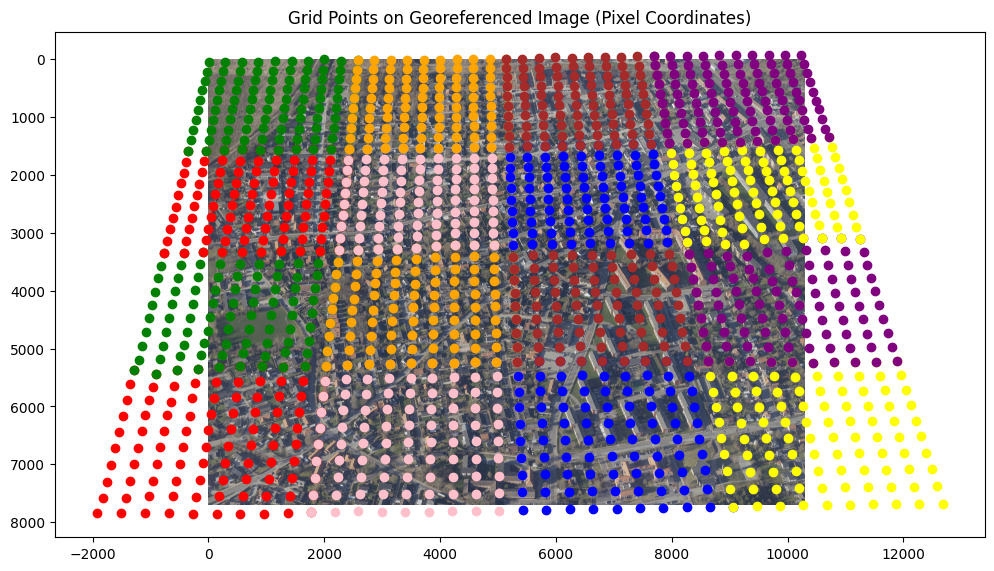

In [8]:
# tiles: list[tile_model.TileData]= image_tiling.split_image_by_latlon(item,4,4)
index = 0;
colors = ['red','pink', 'blue', 'yellow','green','orange','brown','purple','red','pink', 'blue', 'yellow','green','orange','brown','purple']
fig, ax = plt.subplots(figsize=(12, 12))
ax.imshow(image)

for id, tile_list in tiles_test.items(): 
    for tile in tile_list: 
        print(f"Processing tile:  {index}")
        tile_bound_latlon = tile.tile_bounds_latlon
        lon_min = tile_bound_latlon['lon_min']
        lon_max = tile_bound_latlon['lon_max']
        lat_min = tile_bound_latlon['lat_min']
        lat_max = tile_bound_latlon['lat_max']
        print (f"Generating lat long within bbx: {lat_min,lon_min,lat_max,lon_max}")
        grid = geo.generate_real_world_points(lon_min,lat_min,lon_max, lat_max)
        lats = grid[:, 1]
        lons = grid[:, 0]
        pixel_coords = [geo.latlon_to_pixel(lat, lon, item) for lat, lon in zip(lats, lons)]
        pixels_x = [pt[0] for pt in pixel_coords]
        pixels_y = [pt[1] for pt in pixel_coords]
        inverted_ys = [image.shape[0] - y for y in pixels_y ]
        color = colors[index]
        ax.scatter(pixels_x, inverted_ys, c=color, marker='o')
        index +=1


ax.set_title('Grid Points on Georeferenced Image (Pixel Coordinates)')

plt.show()   

# Tiling and saving to .h5

In [ ]:
tiles_test = geo.split_image_by_latlon(item,image,4,4)
tiles_test

{'2023_82_16_2_0004_00003756': [TileData(tile_image_path='../data/tiles/2023_82_16_2_0004_00003756/tile[10.02735779313822,56.44316104991162,10.032126069873804,56.445658342978376].jpeg', tile_bounds_latlon={'lat_min': np.float64(56.44316104991162), 'lat_max': np.float64(56.445658342978376), 'lon_min': np.float64(10.02735779313822), 'lon_max': np.float64(10.032126069873804)}, pixel_bounds={'x_min': 0, 'x_max': 2031, 'y_min': 0, 'y_max': 2398}, homography=array([[ 6.30327663e-05, -3.85900830e-04,  1.00297968e+01],
         [ 3.47319340e-04, -2.16949189e-03,  5.64433065e+01],
         [ 6.15364831e-06, -3.84527749e-05,  1.00000000e+00]])),
  TileData(tile_image_path='../data/tiles/2023_82_16_2_0004_00003756/tile[10.032126069873804,56.44316104991162,10.03689434660939,56.445658342978376].jpeg', tile_bounds_latlon={'lat_min': np.float64(56.44316104991162), 'lat_max': np.float64(56.445658342978376), 'lon_min': np.float64(10.032126069873804), 'lon_max': np.float64(10.03689434660939)}, pixel_bou

In [14]:
from data import data_access

data_access.save_to_file(tiles_test,'tiles_and_homographies.h5')

Saving group: 2023_82_16_2_0004_00003756
Data successfully saved to 'tiles_and_homographies.h5'


In [19]:
getmeatilefromfile_test = geo.get_tile_for_pixel(300, 300, stac_item_id)
getmeatilefromfile_test

Tiles loaded from storage.
[{'homography': array([[ 6.30327663e-05, -3.85900830e-04,  1.00297968e+01],
       [ 3.47319340e-04, -2.16949189e-03,  5.64433065e+01],
       [ 6.15364831e-06, -3.84527749e-05,  1.00000000e+00]]), 'pixel_bounds': {'x_max': np.int64(2031), 'x_min': np.int64(0), 'y_max': np.int64(2398), 'y_min': np.int64(0)}, 'tile_bounds_latlon': {'lat_max': np.float64(56.445658342978376), 'lat_min': np.float64(56.44316104991162), 'lon_max': np.float64(10.032126069873804), 'lon_min': np.float64(10.02735779313822)}, 'tile_image_path': ''}, {'homography': array([[ 3.23415439e-05, -3.74561010e-04,  1.00297283e+01],
       [ 1.74447221e-04, -2.10574508e-03,  5.64433097e+01],
       [ 3.09086838e-06, -3.73231841e-05,  1.00000000e+00]]), 'pixel_bounds': {'x_max': np.int64(5431), 'x_min': np.int64(1774), 'y_max': np.int64(2474), 'y_min': np.int64(0)}, 'tile_bounds_latlon': {'lat_max': np.float64(56.445658342978376), 'lat_min': np.float64(56.44316104991162), 'lon_max': np.float64(10.

{'homography': array([[ 6.30327663e-05, -3.85900830e-04,  1.00297968e+01],
        [ 3.47319340e-04, -2.16949189e-03,  5.64433065e+01],
        [ 6.15364831e-06, -3.84527749e-05,  1.00000000e+00]]),
 'pixel_bounds': {'x_max': np.int64(2031),
  'x_min': np.int64(0),
  'y_max': np.int64(2398),
  'y_min': np.int64(0)},
 'tile_bounds_latlon': {'lat_max': np.float64(56.445658342978376),
  'lat_min': np.float64(56.44316104991162),
  'lon_max': np.float64(10.032126069873804),
  'lon_min': np.float64(10.02735779313822)},
 'tile_image_path': ''}

In [21]:
stac_item_id_horsens = skraafoto.fetch_skraafoto_item('2023_82_23_2_0012_00001362')

In [24]:
tiles_horsens = geo.split_image_by_latlon(stac_item_id_horsens,4,4)

In [26]:
stac_item_id_copenhagen = skraafoto.fetch_skraafoto_item('2023_84_40_2_0208_00114023')
tiles_copenhagen = geo.split_image_by_latlon(stac_item_id_copenhagen,4,4)

Time elapsed: 0.1621 ms
Time elapsed: 0.3431 ms
Time elapsed: 0.3409 ms
Time elapsed: 0.3328 ms
Time elapsed: 0.3159 ms
Time elapsed: 0.4730 ms
Time elapsed: 0.4649 ms
Time elapsed: 0.3231 ms
Time elapsed: 0.3099 ms
Time elapsed: 0.2911 ms
Time elapsed: 0.4148 ms
Time elapsed: 0.2999 ms
Time elapsed: 0.4401 ms
Time elapsed: 0.3059 ms
Time elapsed: 0.2179 ms
Time elapsed: 0.2499 ms


In [31]:
stac_item_id_aarhus = skraafoto.fetch_skraafoto_item('2023_82_24_2_0012_00000537')
tiles_copenhagen = geo.split_image_by_latlon(stac_item_id_copenhagen,4,4)

Time elapsed: 0.2310 ms
latlong to pixel - Time elapsed: 19877.7189 ms
Comp. Homoography Time elapsed: 0.6680 ms
Time elapsed: 0.3011 ms
latlong to pixel - Time elapsed: 22509.5370 ms
Comp. Homoography Time elapsed: 0.4289 ms
Time elapsed: 0.2961 ms
latlong to pixel - Time elapsed: 20287.4582 ms
Comp. Homoography Time elapsed: 0.5572 ms
Time elapsed: 0.1719 ms
latlong to pixel - Time elapsed: 17636.5891 ms
Comp. Homoography Time elapsed: 0.5662 ms
Time elapsed: 0.1302 ms
latlong to pixel - Time elapsed: 16316.3338 ms
Comp. Homoography Time elapsed: 0.6118 ms
Time elapsed: 0.3030 ms
latlong to pixel - Time elapsed: 23259.8929 ms
Comp. Homoography Time elapsed: 0.5319 ms
Time elapsed: 0.1948 ms
latlong to pixel - Time elapsed: 21555.6870 ms
Comp. Homoography Time elapsed: 0.2689 ms
Time elapsed: 0.3970 ms
latlong to pixel - Time elapsed: 19812.6719 ms
Comp. Homoography Time elapsed: 0.5448 ms
Time elapsed: 0.3328 ms
latlong to pixel - Time elapsed: 26816.0431 ms
Comp. Homoography Time el

In [32]:
stac_item_id_aarhus = skraafoto.fetch_skraafoto_item('2023_82_24_2_0012_00000537')
tiles_aarhus = geo.split_image_by_latlon(stac_item_id_aarhus,4,4)

Time elapsed: 0.2830 ms
latlong to pixel - Time elapsed: 22981.3690 ms
Comp. Homoography Time elapsed: 0.3412 ms
Time elapsed: 0.1681 ms
latlong to pixel - Time elapsed: 24598.1541 ms
Comp. Homoography Time elapsed: 0.6440 ms
Time elapsed: 0.3221 ms
latlong to pixel - Time elapsed: 28388.2740 ms
Comp. Homoography Time elapsed: 0.7439 ms
Time elapsed: 0.2940 ms
latlong to pixel - Time elapsed: 20797.3592 ms
Comp. Homoography Time elapsed: 0.6447 ms
Time elapsed: 0.3750 ms
latlong to pixel - Time elapsed: 21359.2229 ms
Comp. Homoography Time elapsed: 0.7207 ms
Time elapsed: 0.4010 ms
latlong to pixel - Time elapsed: 17336.6439 ms
Comp. Homoography Time elapsed: 0.7470 ms
Time elapsed: 0.1373 ms
latlong to pixel - Time elapsed: 19320.2682 ms
Comp. Homoography Time elapsed: 0.5121 ms
Time elapsed: 0.1872 ms
latlong to pixel - Time elapsed: 18411.9999 ms
Comp. Homoography Time elapsed: 0.7589 ms
Time elapsed: 0.4048 ms
latlong to pixel - Time elapsed: 28104.3658 ms
Comp. Homoography Time el

In [33]:
tiles_aarhus = geo.split_image_by_latlon(stac_item_id_aarhus,4,4)

Elevation: Time elapsed: 173.5129 ms
Elevation: Time elapsed: 147.9149 ms
Elevation: Time elapsed: 160.6212 ms
Elevation: Time elapsed: 144.2177 ms
Time elapsed: 0.1349 ms
Elevation: Time elapsed: 155.6201 ms
Elevation: Time elapsed: 182.8568 ms
Elevation: Time elapsed: 148.0238 ms
Elevation: Time elapsed: 172.4188 ms
Elevation: Time elapsed: 136.0521 ms
Elevation: Time elapsed: 161.0873 ms
Elevation: Time elapsed: 156.9638 ms
Elevation: Time elapsed: 153.5859 ms
Elevation: Time elapsed: 156.1627 ms
Elevation: Time elapsed: 155.6849 ms
Elevation: Time elapsed: 174.6430 ms
Elevation: Time elapsed: 171.8071 ms
Elevation: Time elapsed: 152.8239 ms
Elevation: Time elapsed: 144.6960 ms
Elevation: Time elapsed: 152.9071 ms
Elevation: Time elapsed: 1174.0460 ms
Elevation: Time elapsed: 145.0391 ms
Elevation: Time elapsed: 164.6171 ms
Elevation: Time elapsed: 165.2150 ms
Elevation: Time elapsed: 147.6350 ms
Elevation: Time elapsed: 144.3348 ms
Elevation: Time elapsed: 146.5781 ms
Elevation: Ti

In [81]:
data_access.save_to_file(tiles_aarhus)

Saving group: 2023_82_24_2_0012_00000537
Data successfully saved to 'tile_data'


In [82]:
data_access.save_to_file(tiles_copenhagen)
data_access.save_to_file(tiles_horsens)

Saving group: 2023_84_40_2_0208_00114023
Data successfully saved to 'tile_data'
Saving group: 2023_82_23_2_0012_00001362
Data successfully saved to 'tile_data'


# Full convertion with accessing saved data 

In [ ]:
img = skraafoto.get_image_from_url(image_handler.extract_selected_image(item))

Random Pixel to Convert: (7613, 216)
Tiles belonging to STAC item ID 2023_82_16_2_0004_00003756 loaded from storage.
Bounding Box in Pixels: x_min=0, x_max=2031, y_min=0, y_max=2398
Checking if (7613, 216) falls inside...

Bounding Box in Pixels: x_min=1774, x_max=5431, y_min=0, y_max=2474
Checking if (7613, 216) falls inside...

Bounding Box in Pixels: x_min=5194, x_max=8259, y_min=4488, y_max=6242
Checking if (7613, 216) falls inside...

Bounding Box in Pixels: x_min=7950, x_max=10300, y_min=4535, y_max=6348
Checking if (7613, 216) falls inside...

Bounding Box in Pixels: x_min=0, x_max=2578, y_min=6112, y_max=7673
Checking if (7613, 216) falls inside...

Bounding Box in Pixels: x_min=2431, x_max=5194, y_min=6145, y_max=7700
Checking if (7613, 216) falls inside...

Bounding Box in Pixels: x_min=5139, x_max=7950, y_min=6184, y_max=7700
Checking if (7613, 216) falls inside...

Bounding Box in Pixels: x_min=7692, x_max=10300, y_min=6242, y_max=7700
Checking if (7613, 216) falls inside..

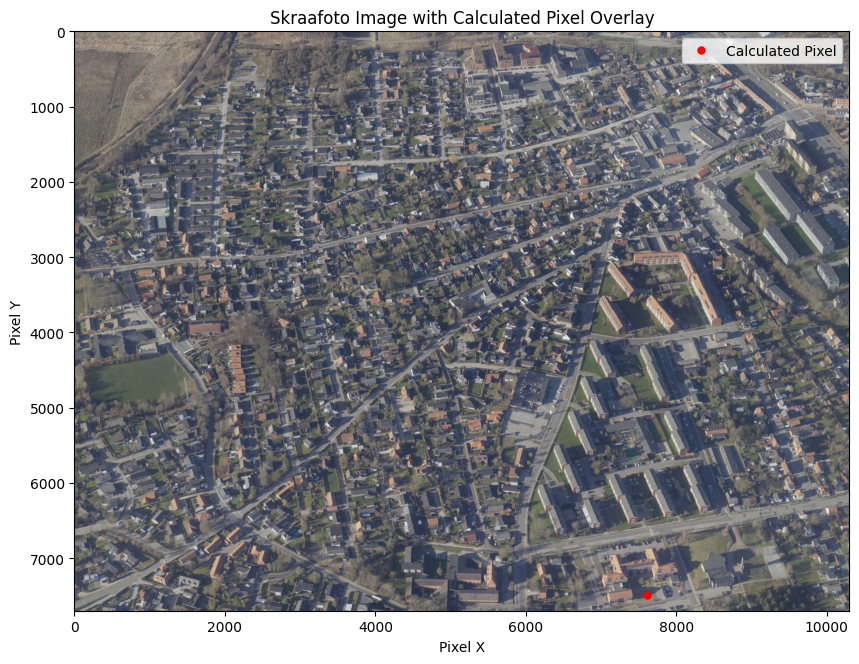

In [ ]:
random_pixel_x = random.randint(0, image.shape[1] - 1)
random_pixel_y = random.randint(0, image.shape[0] - 1)

print(f"Random Pixel to Convert: {random_pixel_x, random_pixel_y}")

tile = geo.get_tile_for_pixel(random_pixel_x, random_pixel_y, stac_item_id)
projected_points = geo.convert_pixel_to_world_homography(random_pixel_x,random_pixel_y, tile['homography'])
print(f"Projected lon lat: {projected_points}")


plots.plot_pixel_on_image([random_pixel_x,random_pixel_y],img)

plots.generate_map_with_projected_point(projected_points[1], projected_points[0],item['bbox'], f'test_pixels:{random_pixel_x, random_pixel_y}')

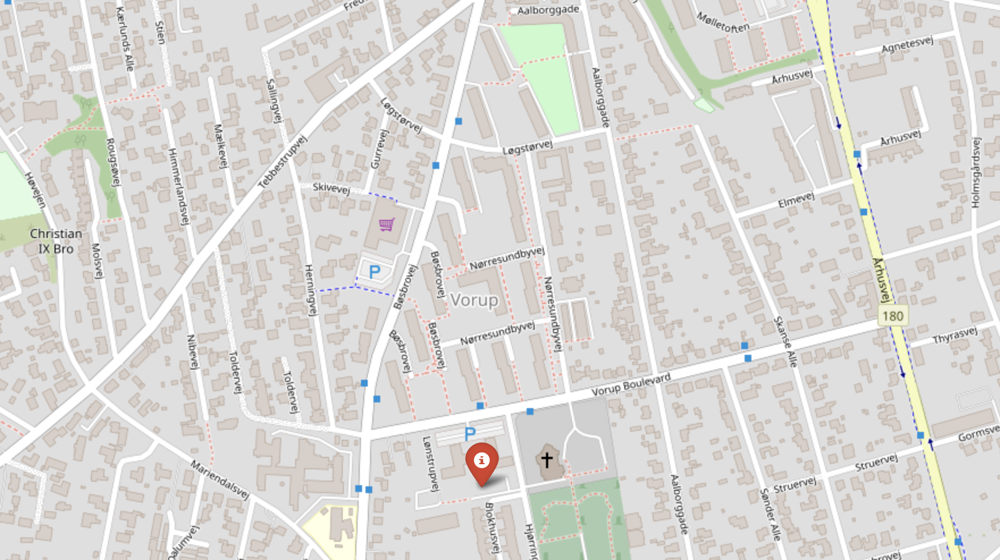

In [88]:
img = skraafoto.get_image_from_url(image_handler.extract_selected_image(stac_item_id_aarhus))

Random Pixel to Convert: (10091, 3359)
Tiles belonging to STAC item ID 2023_82_24_2_0012_00000537 loaded from storage.
Bounding Box in Pixels: x_min=0, x_max=2810, y_min=0, y_max=3264
Checking if (10091, 3359) falls inside...

Bounding Box in Pixels: x_min=2459, x_max=7375, y_min=0, y_max=3284
Checking if (10091, 3359) falls inside...

Bounding Box in Pixels: x_min=7140, x_max=11299, y_min=6110, y_max=8546
Checking if (10091, 3359) falls inside...

Bounding Box in Pixels: x_min=10929, x_max=14144, y_min=6136, y_max=8569
Checking if (10091, 3359) falls inside...

Bounding Box in Pixels: x_min=0, x_max=3550, y_min=8431, y_max=10552
Checking if (10091, 3359) falls inside...

Bounding Box in Pixels: x_min=3342, x_max=7140, y_min=8467, y_max=10560
Checking if (10091, 3359) falls inside...

Bounding Box in Pixels: x_min=7084, x_max=10929, y_min=8493, y_max=10560
Checking if (10091, 3359) falls inside...

Bounding Box in Pixels: x_min=10607, x_max=14144, y_min=8546, y_max=10560
Checking if (1

/Users/kristinajassova/Library/Caches/pypoetry/virtualenvs/bachelor-project-18kCXu1E-py3.12/lib/python3.12/site-packages/PIL/Image.py:3402: DecompressionBombWarning: Image size (149360640 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


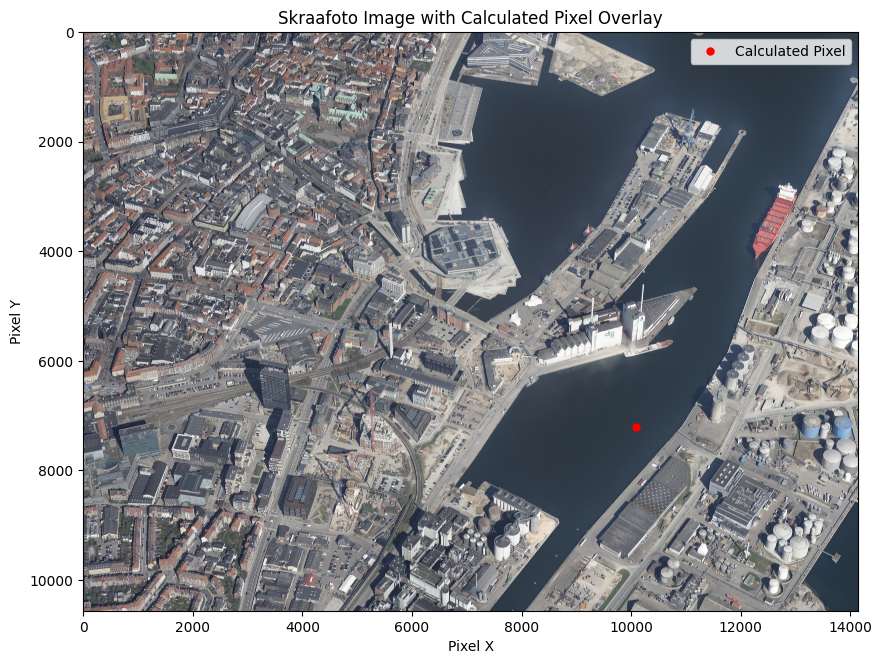

In [89]:
random_pixel_x = random.randint(0, image.shape[1] - 1)
random_pixel_y = random.randint(0, image.shape[0] - 1)

print(f"Random Pixel to Convert: {random_pixel_x, random_pixel_y}")

tile = geo.get_tile_for_pixel(random_pixel_x, random_pixel_y, '2023_82_24_2_0012_00000537')
projected_points = geo.convert_pixel_to_world_homography(random_pixel_x,random_pixel_y, tile['homography'])
print(f"Projected lon lat: {projected_points}")

plots.plot_pixel_on_image([random_pixel_x,random_pixel_y],img)

plots.generate_map_with_projected_point(projected_points[1], projected_points[0],item['bbox'], f'test_pixels:{random_pixel_x, random_pixel_y}')

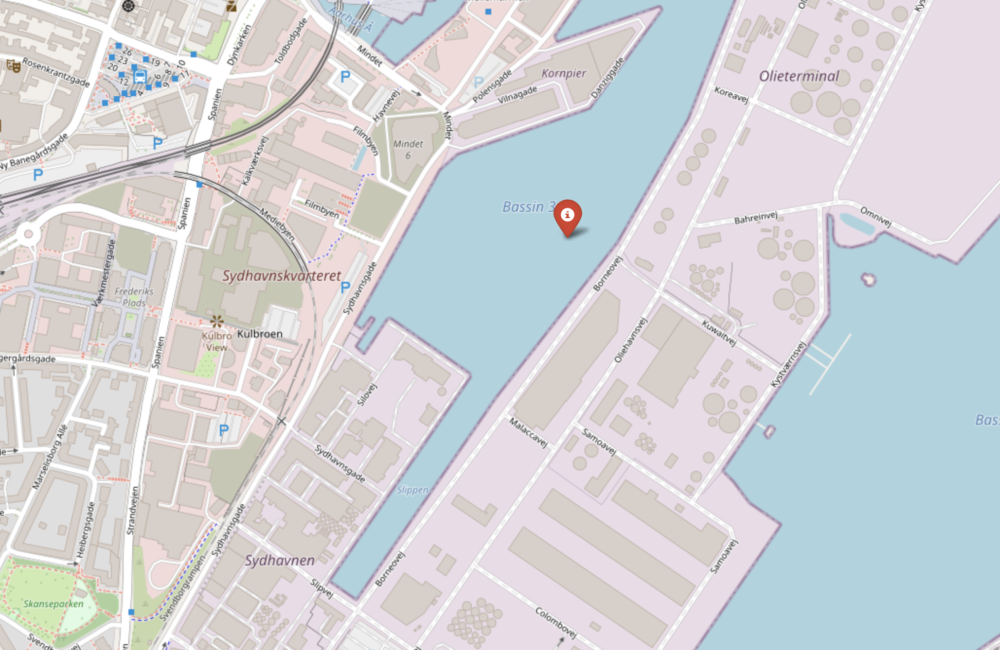

# Test corners

In [ ]:
img = skraafoto.get_image_from_url(image_handler.extract_selected_image(stac_item_id_copenhagen))

Random Pixel to Convert: (100, 7000)
Tiles belonging to STAC item ID 2023_84_40_2_0208_00114023 loaded from storage.
Bounding Box in Pixels: x_min=0, x_max=2553, y_min=0, y_max=2577
Checking if (100, 7000) falls inside...

Bounding Box in Pixels: x_min=2393, x_max=6540, y_min=0, y_max=2734
Checking if (100, 7000) falls inside...

Bounding Box in Pixels: x_min=5887, x_max=9407, y_min=5119, y_max=7210
Checking if (100, 7000) falls inside...

Bounding Box in Pixels: x_min=8950, x_max=11508, y_min=5223, y_max=7276
Checking if (100, 7000) falls inside...

Bounding Box in Pixels: x_min=0, x_max=2885, y_min=6905, y_max=8628
Checking if (100, 7000) falls inside...

Projected lon lat: (np.float64(12.559215511884736), np.float64(55.677027353198056))


/Users/kristinajassova/Library/Caches/pypoetry/virtualenvs/bachelor-project-18kCXu1E-py3.12/lib/python3.12/site-packages/PIL/Image.py:3402: DecompressionBombWarning: Image size (99291024 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


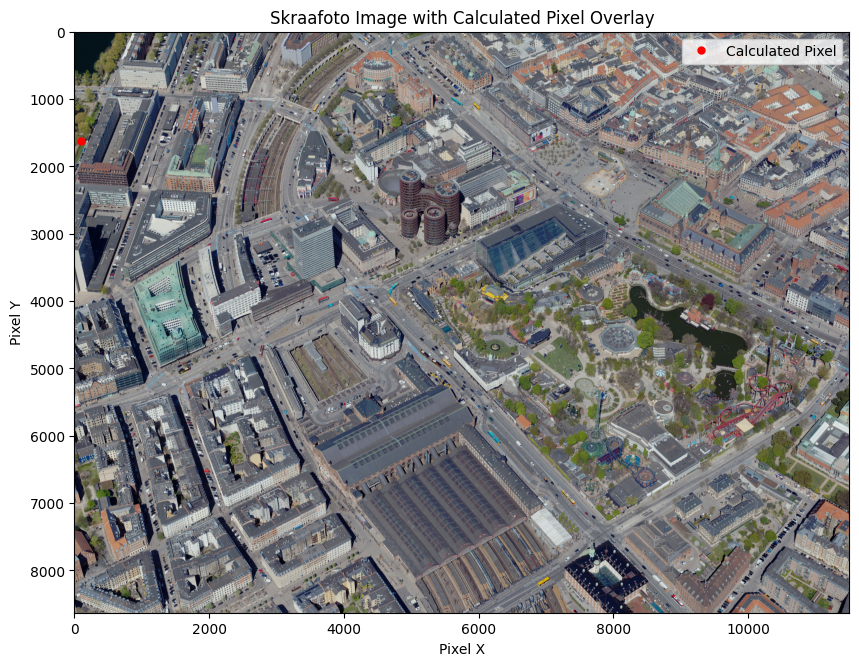

In [83]:
random_pixel_x = 100
random_pixel_y = 7000

print(f"Random Pixel to Convert: {random_pixel_x, random_pixel_y}")

tile = geo.get_tile_for_pixel(random_pixel_x, random_pixel_y, '2023_84_40_2_0208_00114023')
projected_points = geo.convert_pixel_to_world_homography(random_pixel_x,random_pixel_y, tile['homography'])
print(f"Projected lon lat: {projected_points}")

plots.plot_pixel_on_image([random_pixel_x,random_pixel_y],img)

plots.generate_map_with_projected_point(projected_points[1], projected_points[0],item['bbox'], f'test_pixels:{random_pixel_x, random_pixel_y}')

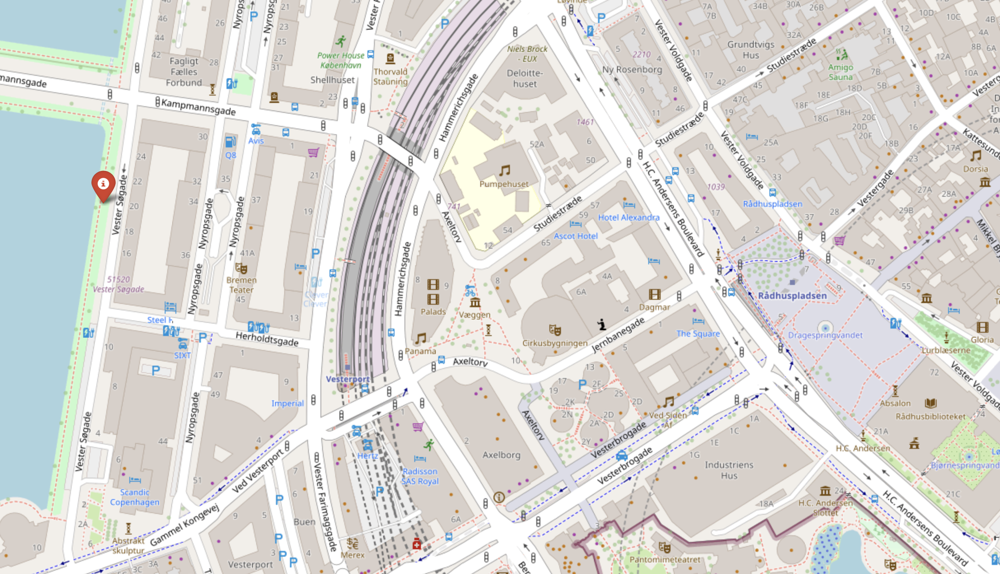

Random Pixel to Convert: (50, 100)
Tiles belonging to STAC item ID 2023_84_40_2_0208_00114023 loaded from storage.
Bounding Box in Pixels: x_min=0, x_max=2553, y_min=0, y_max=2577
Checking if (50, 100) falls inside...

Projected lon lat: (np.float64(12.560319267343138), np.float64(55.6711933939048))


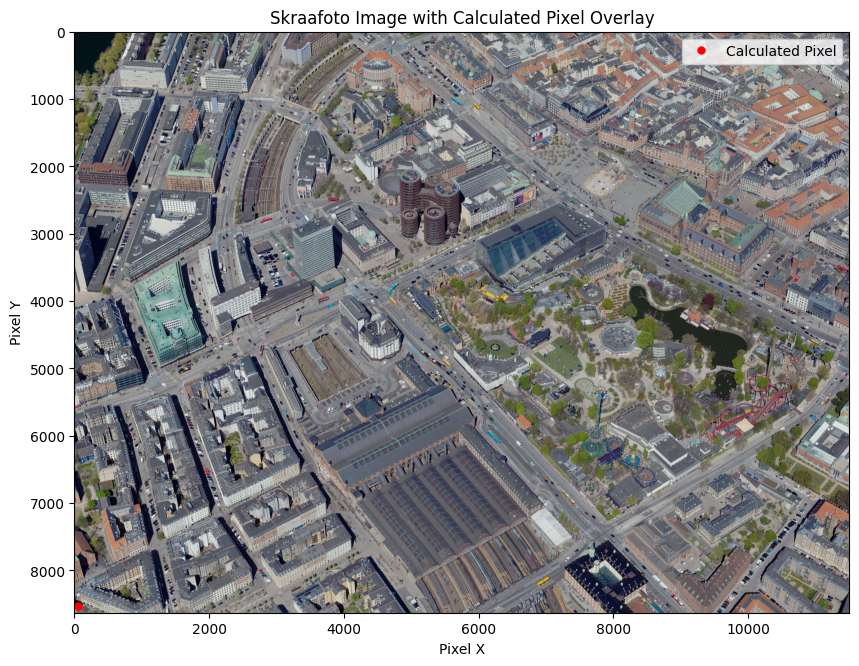

In [84]:
random_pixel_x = 50
random_pixel_y = 100

print(f"Random Pixel to Convert: {random_pixel_x, random_pixel_y}")

tile = geo.get_tile_for_pixel(random_pixel_x, random_pixel_y, '2023_84_40_2_0208_00114023')
projected_points = geo.convert_pixel_to_world_homography(random_pixel_x,random_pixel_y, tile['homography'])
print(f"Projected lon lat: {projected_points}")

plots.plot_pixel_on_image([random_pixel_x,random_pixel_y],img)

plots.generate_map_with_projected_point(projected_points[1], projected_points[0],item['bbox'], f'test_pixels:{random_pixel_x, random_pixel_y}')

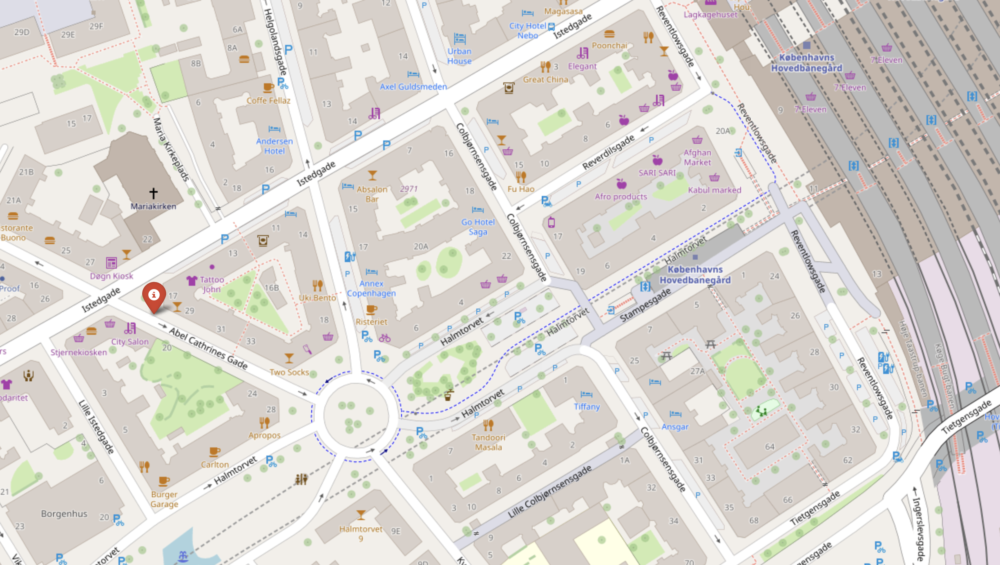